In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
        pass

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ravikushwah095/messy-data-predicting-sales/messy_train_data.csv
/kaggle/input/datasets/ravikushwah095/messy-data-predicting-sales/messy_test_data.csv


In [2]:

import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

train_path = "/kaggle/input/datasets/ravikushwah095/messy-data-predicting-sales/messy_train_data.csv"
test_path = "/kaggle/input/datasets/ravikushwah095/messy-data-predicting-sales/messy_test_data.csv"

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print("Training Data Shape:", train.shape)
print("Testing Data Shape:", test.shape)

print("\nTraining Data:")
display(train.head())

print("\nTesting Data:")
display(test.head())


Training Data Shape: (8000, 8)
Testing Data Shape: (2000, 7)

Training Data:


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,Sales (Units),ID,Timestamp,Notes
0,106572.0,2.573174871146172,2614.3781948587675,5.275680,6340,9254,2021-11-27,Pending
1,77583.0,0.9394984315675532,4975.962514379572,8.756268,5793,1561,2022-02-13,Review
2,92832.0,2.1761012652155296,4107.769534318886,6.454727,8104,1670,2023-09-25,Pending
3,53565.0,1.4783757541486553,4293.330464613049,4.312813,7293,6087,2023-02-15,Review
4,121079.0,3.3741976179329356,5343.549440897207,3.769047,14396,6669,2023-05-28,NaN



Testing Data:


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,ID,Timestamp,Notes
0,179136.0,2.5570425842061986,3975.099954173261,1.803620,6252,2021-10-08,Good
1,68888.0,3.451254744278324,5392.048613170361,2.993966,4684,2021-10-01,Good
2,89520.0,0.7342357926528821,5850.470394900652,4.525990,1731,2021-06-24,NaN
3,100048.0,1.5972073367018218,5792.432498712002,5.051500,4742,2021-11-22,NaN
4,132229.0,1.3874265375395036,5095.269891920688,3.580921,4521,2021-07-19,Review


In [3]:

# Inspect columns, data types, missing values and duplicates

print("Column Names:")
print(train.columns.tolist())

print("\nTraining Data Information:")
train.info()

print("\nMissing Values:")
display(train.isnull().sum().to_frame("Missing_Count"))

print("\nDuplicate Rows:", train.duplicated().sum())

print("\nUnique Values Per Column:")
display(train.nunique().to_frame("Unique_Count"))

print("\nStatistical Summary:")
display(train.describe(include="all").T)


Column Names:
['Followers', 'EngagementRate (%)', 'AdSpend (GBP)', 'ContentQuality', 'Sales (Units)', 'ID', 'Timestamp', 'Notes']

Training Data Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Followers           7840 non-null   float64
 1   EngagementRate (%)  7840 non-null   object 
 2   AdSpend (GBP)       7841 non-null   object 
 3   ContentQuality      7840 non-null   float64
 4   Sales (Units)       8000 non-null   int64  
 5   ID                  8000 non-null   int64  
 6   Timestamp           8000 non-null   object 
 7   Notes               5348 non-null   object 
dtypes: float64(2), int64(2), object(4)
memory usage: 500.1+ KB

Missing Values:


,Missing_Count
Followers,160
EngagementRate (%),160
AdSpend (GBP),159
ContentQuality,160
Sales (Units),0
ID,0
Timestamp,0
Notes,2652



Duplicate Rows: 0

Unique Values Per Column:


,Unique_Count
Followers,7403
EngagementRate (%),7800
AdSpend (GBP),7815
ContentQuality,7840
Sales (Units),5582
ID,8000
Timestamp,1000
Notes,4



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Followers,7840.0,NaN,NaN,NaN,1111104.467602,40130384.889415,20.0,78002.5,99120.5,119865.5,1629447388.0
EngagementRate (%),7840,7800,1.75%,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AdSpend (GBP),7841,7815,1000.0,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ContentQuality,7840.0,NaN,NaN,NaN,5.492899,2.608038,1.000151,3.227357,5.468786,7.780281,9.999749
Sales (Units),8000.0,NaN,NaN,NaN,10544.674375,2808.151485,590.0,8642.25,10500.0,12459.0,20263.0
ID,8000.0,NaN,NaN,NaN,5011.506875,2887.649416,1.0,2511.75,5013.5,7504.25,9999.0
Timestamp,8000,1000,2022-09-17,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Notes,5348,4,Pending,1367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:

# Inspect messy values before cleaning

# Show sample values from columns stored as text
for col in ['EngagementRate (%)', 'AdSpend (GBP)', 'Notes', 'Timestamp']:
    print(f"\n--- {col} ---")
    print(train[col].dropna().astype(str).sample(
        min(15, train[col].notna().sum()),
        random_state=42
    ).tolist())

# Check Notes categories
print("\nNotes value counts:")
print(train['Notes'].value_counts(dropna=False))

# Check follower extremes
print("\nLowest Followers:")
print(train['Followers'].nsmallest(10).tolist())

print("\nHighest Followers:")
print(train['Followers'].nlargest(15).tolist())

# Check ContentQuality range
print("\nContentQuality percentiles:")
print(train['ContentQuality'].quantile(
    [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1]
))

# Check ID and target relationship
print("\nID vs Sales correlation:")
print(train[['ID', 'Sales (Units)']].corr())

# Check test columns
print("\nTest columns:", test.columns.tolist())
print("Test missing values:")
print(test.isnull().sum())



--- EngagementRate (%) ---
['3.7794265624957264', '1.9166037176031652', '1.3969573652775822', '3.337326433462991', '0.759574780625947', '3.984350530010679', '4.4615668813339555', '1.2773959070538514', '3.392357155851258', '0.949716079558788', '4.337627499909059', '1.3838633906661548', '1.8124644672542165', '4.044689288988884', '4.55%']

--- AdSpend (GBP) ---
['£5364', '£4861', '£3811', '£3347', '£3911', '£4482', '£6483', '£5995', '£4765', '£4787', '£3684', '£5360', '£4338', '£4802', '£5561']

--- Notes ---
['Good', 'Good', 'Check', 'Good', 'Review', 'Good', 'Check', 'Review', 'Check', 'Good', 'Review', 'Pending', 'Review', 'Pending', 'Pending']

--- Timestamp ---
['2023-07-15', '2022-09-09', '2021-04-21', '2023-01-25', '2022-10-16', '2023-09-14', '2021-04-03', '2021-03-29', '2022-12-17', '2023-09-20', '2021-10-16', '2023-02-01', '2021-02-15', '2021-06-18', '2023-02-06']

Notes value counts:
Notes
NaN        2652
Pending    1367
Check      1358
Review     1329
Good       1294
Name: cou

In [5]:

# Preserve original datasets
train_clean = train.copy()
test_clean = test.copy()

# Convert EngagementRate to numeric
for df in [train_clean, test_clean]:
    df['EngagementRate (%)'] = pd.to_numeric(
        df['EngagementRate (%)']
        .astype('string')
        .str.replace('%', '', regex=False)
        .str.replace(',', '', regex=False)
        .str.strip(),
        errors='coerce'
    )

# Convert AdSpend to numeric
for df in [train_clean, test_clean]:
    df['AdSpend (GBP)'] = pd.to_numeric(
        df['AdSpend (GBP)']
        .astype('string')
        .str.replace('£', '', regex=False)
        .str.replace(',', '', regex=False)
        .str.strip(),
        errors='coerce'
    )

#Inspect suspicious Followers values BEFORE changing them
print("Train Followers > 200,000:",
      (train_clean['Followers'] > 200_000).sum())

print("Train Followers > 1 million:",
      (train_clean['Followers'] > 1_000_000).sum())

print("Test Followers > 200,000:",
      (test_clean['Followers'] > 200_000).sum())

print("Train negative AdSpend:",
      (train_clean['AdSpend (GBP)'] < 0).sum())

#Convert Timestamp and create date features
for df in [train_clean, test_clean]:
    df['Timestamp'] = pd.to_datetime(
        df['Timestamp'], errors='coerce'
    )

    df['Year'] = df['Timestamp'].dt.year
    df['Month'] = df['Timestamp'].dt.month
    df['DayOfWeek'] = df['Timestamp'].dt.dayofweek

#Inspect Notes against Sales
print("\nAverage sales by Notes:")
print(train_clean.groupby(
    'Notes', dropna=False
)['Sales (Units)'].agg(['count', 'mean', 'median']))

#Verify cleaned data types and missing values
print("\nCleaned dtypes:")
print(train_clean.dtypes)

print("\nRemaining missing values:")
print(train_clean.isnull().sum())


Train Followers > 200,000: 5
Train Followers > 1 million: 5
Test Followers > 200,000: 5
Train negative AdSpend: 3

Average sales by Notes:
         count          mean   median
Notes                                
Check     1358  10677.273196  10547.0
Good      1294  10492.953632  10379.0
Pending   1367  10425.931968  10497.0
Review    1329  10519.674191  10410.0
NaN       2652  10575.746606  10599.0

Cleaned dtypes:
Followers                    float64
EngagementRate (%)           Float64
AdSpend (GBP)                Float64
ContentQuality               float64
Sales (Units)                  int64
ID                             int64
Timestamp             datetime64[ns]
Notes                         object
Year                           int32
Month                          int32
DayOfWeek                      int32
dtype: object

Remaining missing values:
Followers              160
EngagementRate (%)     160
AdSpend (GBP)          159
ContentQuality         160
Sales (Units)         

In [6]:

# Handle invalid values and build a baseline pipeline

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

train_model = train_clean.copy()
test_model = test_clean.copy()

for df in [train_model, test_model]:
    # Extreme values are inconsistent with the observed follower distribution
    df.loc[df['Followers'] > 1_000_000, 'Followers'] = np.nan

    # Impossible or invalid values
    df.loc[df['Followers'] < 0, 'Followers'] = np.nan
    df.loc[
        (df['EngagementRate (%)'] < 0) |
        (df['EngagementRate (%)'] > 100),
        'EngagementRate (%)'
    ] = np.nan
    df.loc[df['AdSpend (GBP)'] < 0, 'AdSpend (GBP)'] = np.nan
    df.loc[
        (df['ContentQuality'] < 1) |
        (df['ContentQuality'] > 10),
        'ContentQuality'
    ] = np.nan

    # Keep missing Notes as an explicit category
    df['Notes'] = df['Notes'].fillna('Unknown')

# Select features; do not use ID or raw Timestamp
numeric_features = [
    'Followers',
    'EngagementRate (%)',
    'AdSpend (GBP)',
    'ContentQuality',
    'Year',
    'Month',
    'DayOfWeek'
]
categorical_features = ['Notes']

features = numeric_features + categorical_features
target = 'Sales (Units)'

X = train_model[features]
y = train_model[target]
X_test = test_model[features]

# Hold out 20% for validation
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Fit imputers only on training split
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train baseline
model.fit(X_train, y_train)
predictions = model.predict(X_valid)

rmse = np.sqrt(mean_squared_error(y_valid, predictions))
mae = mean_absolute_error(y_valid, predictions)
r2 = r2_score(y_valid, predictions)

print(f"Validation RMSE: {rmse:.2f}")
print(f"Validation MAE:  {mae:.2f}")
print(f"Validation R²:   {r2:.4f}")


Validation RMSE: 2115.28
Validation MAE:  1690.30
Validation R²:   0.4369


In [7]:

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

models = {
    'Dummy Baseline': DummyRegressor(strategy='mean'),

    'Random Forest': RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    'Extra Trees': ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        loss='squared_error',
        random_state=42
    )
}

results = []
fitted_models = {}

for name, regressor in models.items():
    pipe = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('regressor', clone(regressor))
    ])

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_valid)

    results.append({
        'Model': name,
        'RMSE': np.sqrt(mean_squared_error(y_valid, pred)),
        'MAE': mean_absolute_error(y_valid, pred),
        'R2': r2_score(y_valid, pred)
    })

    fitted_models[name] = pipe

results_df = pd.DataFrame(results).sort_values('RMSE')
print(results_df.to_string(index=False))


            Model        RMSE         MAE        R2
Gradient Boosting 2079.912782 1658.117501  0.455561
      Extra Trees 2112.256195 1684.649827  0.438497
    Random Forest 2115.283880 1690.297525  0.436886
   Dummy Baseline 2820.177783 2249.700162 -0.000948


In [8]:

from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

gb_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('regressor', GradientBoostingRegressor(random_state=42))
])

param_distributions = {
    'regressor__n_estimators': [100, 200, 300, 400],
    'regressor__learning_rate': [0.02, 0.03, 0.05, 0.08, 0.1],
    'regressor__max_depth': [1, 2, 3],
    'regressor__min_samples_leaf': [2, 5, 10, 20],
    'regressor__subsample': [0.7, 0.85, 1.0],
    'regressor__loss': ['squared_error', 'huber']
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)

print(f"\nBest 5-fold CV RMSE: {-search.best_score_:.2f}")

# Evaluate tuned model on the untouched validation split
best_model = search.best_estimator_
valid_pred = best_model.predict(X_valid)

print("\nValidation performance after tuning:")
print(f"RMSE: {np.sqrt(mean_squared_error(y_valid, valid_pred)):.2f}")
print(f"MAE:  {mean_absolute_error(y_valid, valid_pred):.2f}")
print(f"R²:   {r2_score(y_valid, valid_pred):.4f}")


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'regressor__subsample': 0.7, 'regressor__n_estimators': 400, 'regressor__min_samples_leaf': 2, 'regressor__max_depth': 1, 'regressor__loss': 'huber', 'regressor__learning_rate': 0.1}

Best 5-fold CV RMSE: 2009.59

Validation performance after tuning:
RMSE: 2075.66
MAE:  1657.56
R²:   0.4578


In [9]:

# Final model: train on all labelled training data

final_model = clone(best_model)
final_model.fit(X, y)

# Predict sales for the test dataset
test_predictions = final_model.predict(X_test)

# Create a results table
predictions_df = pd.DataFrame({
    'ID': test_model['ID'],
    'Predicted Sales (Units)': np.round(test_predictions, 0).astype(int)
})

print(predictions_df.head(10))
print("\nNumber of test predictions:", len(predictions_df))
print("\nPrediction summary:")
print(predictions_df['Predicted Sales (Units)'].describe())

# Save predictions for your project records
predictions_df.to_csv(
    '/kaggle/working/sales_predictions.csv',
    index=False
)

print("\nSaved: /kaggle/working/sales_predictions.csv")


     ID  Predicted Sales (Units)
0  6252                    12713
1  4684                     9052
2  1731                    10035
3  4742                    10705
4  4521                    11451
5  6340                     9351
6   576                    10662
7  5202                    11617
8  6363                    12694
9   439                    14216

Number of test predictions: 2000

Prediction summary:
count     2000.00000
mean     10479.80400
std       1935.26852
min       4879.00000
25%       9168.00000
50%      10487.50000
75%      11744.25000
max      17116.00000
Name: Predicted Sales (Units), dtype: float64

Saved: /kaggle/working/sales_predictions.csv


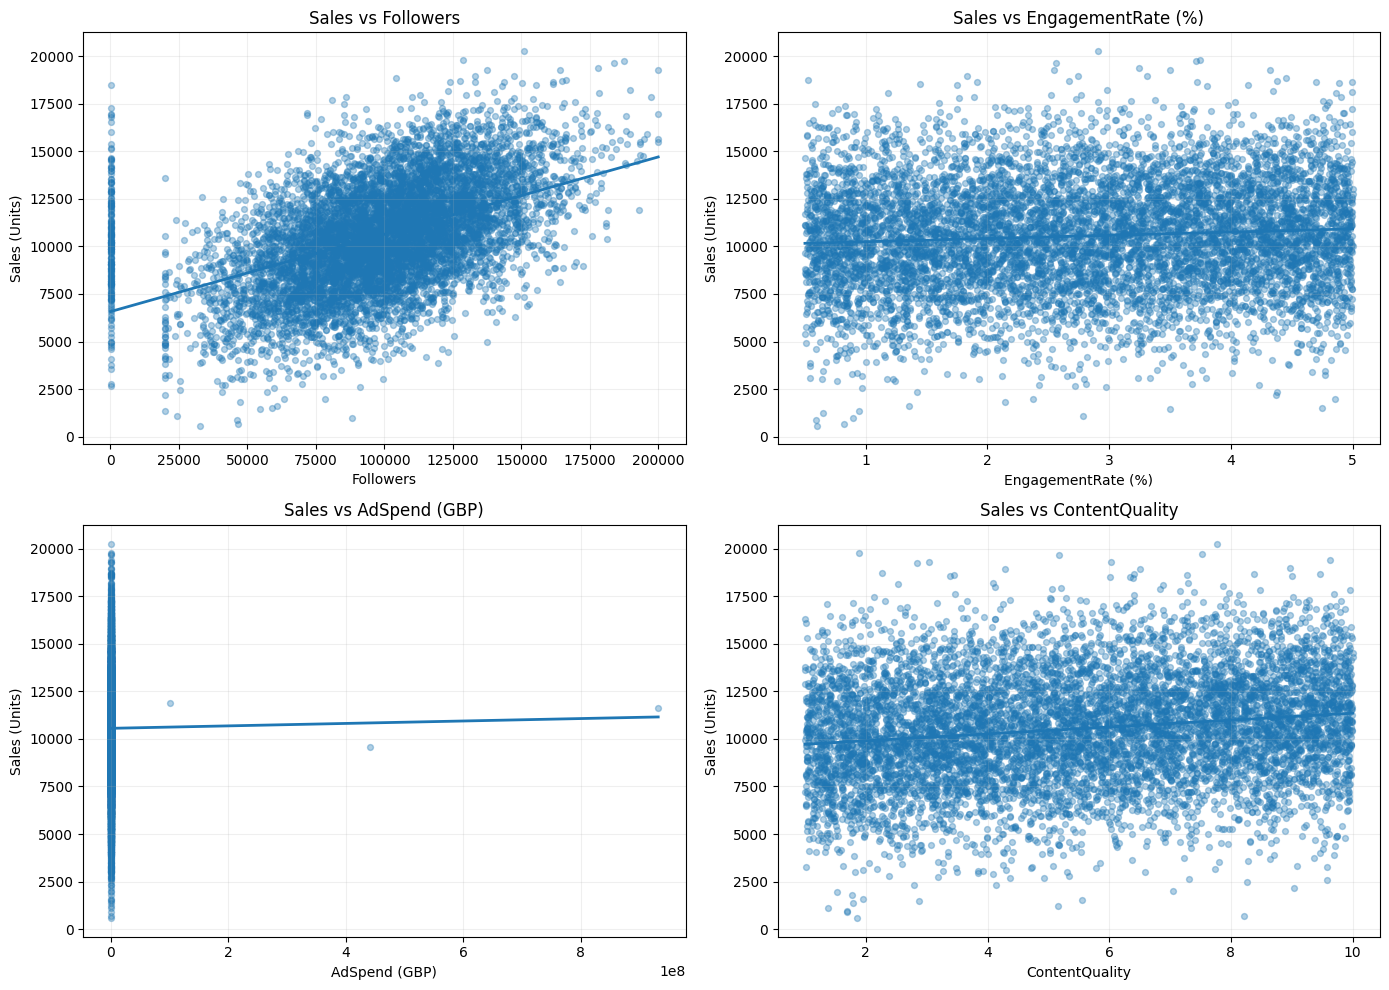

Correlation with Sales:
Sales (Units)         1.000000
Followers             0.485495
ContentQuality        0.168511
EngagementRate (%)    0.078425
AdSpend (GBP)         0.002678
Name: Sales (Units), dtype: float64

Sales by ContentQuality:
                count     mean   median
ContentQuality                         
1.000151            1  13779.0  13779.0
1.001620            1  16309.0  16309.0
1.005353            1  13600.0  13600.0
1.005516            1   9919.0   9919.0
1.006214            1  12859.0  12859.0
...               ...      ...      ...
9.991743            1  10889.0  10889.0
9.992609            1  11554.0  11554.0
9.999015            1  14535.0  14535.0
9.999749            1  14296.0  14296.0
NaN               160  11140.1  11065.0

[7841 rows x 3 columns]


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Existing cleaned training data
eda_df = train_model.copy()

# Sales ko numeric ensure karo
eda_df['Sales (Units)'] = pd.to_numeric(
    eda_df['Sales (Units)'], errors='coerce'
)

features_to_plot = [
    'Followers',
    'EngagementRate (%)',
    'AdSpend (GBP)',
    'ContentQuality'
]

# 4 graphs
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, feature in zip(axes, features_to_plot):
    temp = eda_df[[feature, 'Sales (Units)']].copy()
    temp[feature] = pd.to_numeric(temp[feature], errors='coerce')
    temp = temp.replace([np.inf, -np.inf], np.nan).dropna()

    ax.scatter(
        temp[feature],
        temp['Sales (Units)'],
        alpha=0.35,
        s=18
    )

    # Overall trend line, when enough distinct values exist
    if len(temp) > 2 and temp[feature].nunique() > 1:
        z = np.polyfit(temp[feature], temp['Sales (Units)'], 1)
        x_line = np.linspace(temp[feature].min(), temp[feature].max(), 100)
        ax.plot(x_line, np.polyval(z, x_line), linewidth=2)

    ax.set_title(f'Sales vs {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Sales (Units)')
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Correlation summary
print("Correlation with Sales:")
print(
    eda_df[features_to_plot + ['Sales (Units)']]
    .corr(numeric_only=True)['Sales (Units)']
    .sort_values(ascending=False)
)

# ContentQuality-wise sales summary
print("\nSales by ContentQuality:")
print(
    eda_df.groupby('ContentQuality', dropna=False)['Sales (Units)']
    .agg(['count', 'mean', 'median'])
    .round(2)
)


Permutation Feature Importance:


,Feature,Importance_Mean,Importance_Std
0,Followers,834.2174,59.4872
1,AdSpend (GBP),554.5258,28.9322
2,ContentQuality,98.0702,4.5703
3,EngagementRate (%),23.9013,7.8951
4,DayOfWeek,0.0671,0.7817
5,Year,-0.3675,0.5298
6,Month,-0.4972,0.3763
7,Notes,-0.5032,0.5377


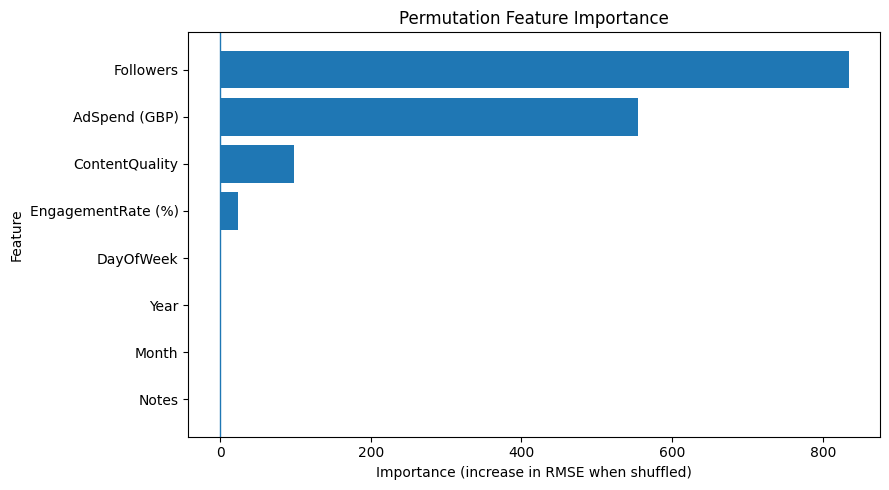

In [11]:

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# best_model should be the tuned, fitted model/pipeline
importance_result = permutation_importance(
    best_model,
    X_valid,
    y_valid,
    scoring='neg_root_mean_squared_error',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X_valid.columns,
    'Importance_Mean': importance_result.importances_mean,
    'Importance_Std': importance_result.importances_std
})

importance_df = importance_df.sort_values(
    'Importance_Mean', ascending=False
).reset_index(drop=True)

print("Permutation Feature Importance:")
display(importance_df.round(4))

# Plot
plot_df = importance_df.sort_values('Importance_Mean')

plt.figure(figsize=(9, 5))
plt.barh(plot_df['Feature'], plot_df['Importance_Mean'])
plt.axvline(0, linewidth=1)
plt.xlabel('Importance (increase in RMSE when shuffled)')
plt.ylabel('Feature')
plt.title('Permutation Feature Importance')
plt.tight_layout()
plt.show()


In [12]:

eda_df = train_model.copy()

# Quality scores ko rounded groups mein compare karein
eda_df['Quality_Band'] = (
    pd.to_numeric(eda_df['ContentQuality'], errors='coerce')
    .round()
)

quality_summary = (
    eda_df.groupby('Quality_Band', dropna=False)['Sales (Units)']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

print("Sales by rounded ContentQuality:")
display(quality_summary)


Sales by rounded ContentQuality:


,count,mean,median
Quality_Band,,,
1.0,433,9665.98,9680.0
2.0,877,9911.15,9848.0
3.0,915,10071.71,9972.0
4.0,846,10280.68,10248.5
5.0,876,10427.95,10378.0
6.0,874,10647.28,10580.5
7.0,822,10818.93,10780.5
8.0,856,11087.86,11149.5
9.0,888,11106.83,11011.0


## Business Insights and Recommendations

The exploratory data analysis and feature importance results provide useful insights for influencer marketing campaign planning.

### 1. Influencer Selection

Follower count has the strongest positive linear correlation with sales (0.4855) and the highest permutation importance (834.2174). Marketing teams can use audience size as one factor when shortlisting influencers. However, follower count should not be the sole selection criterion because audience relevance, engagement, content quality, and campaign cost may also matter.

### 2. Advertising Budget Planning

AdSpend has almost zero linear correlation with sales (0.0027), yet it is the second most important feature in the trained model, with permutation importance of 554.5258. This difference suggests that a simple linear relationship may not fully describe how advertising expenditure relates to sales. The data also contains extreme spend values, so further investigation and validation are recommended before making budget decisions.

### 3. Content Quality

Average sales generally increased across rounded ContentQuality groups, from approximately 9,665.98 units at score 1 to 11,250.83 units at score 10. ContentQuality also contributed to model predictions, although its permutation importance was lower than that of Followers and AdSpend. Marketing teams can continue evaluating content quality alongside other campaign characteristics.

### 4. Engagement Rate

EngagementRate had a weak linear correlation with sales (0.0784) and a relatively small permutation importance (23.9013). This indicates limited additional predictive value in the current model and evaluation setting. It does not prove that engagement is unimportant in every marketing scenario.

### 5. Model-Based Campaign Comparison

The trained model can estimate expected unit sales for candidate campaigns. Teams can compare these estimates with campaign budgets, product margins, and inventory availability before deciding which campaigns to test. Since predictions are estimates, a controlled pilot campaign and comparison with actual sales should precede major spending decisions.

### 6. Reusable Prediction Pipeline

The solution combines data cleaning, invalid-value handling, missing-value imputation, categorical encoding, model training, and prediction generation. The same preprocessing and trained model can be applied to new campaign records, provided the input schema and cleaning rules remain consistent.

Before production deployment, the pipeline should include input validation, monitoring for data drift, periodic evaluation against actual sales, and retraining when necessary.

### Limitations

Permutation importance measures how much a trained model relies on a feature for predictive performance; it does not establish causation. Correlations also describe associations rather than causal effects. The model's validation R² is approximately 0.458, so a substantial portion of sales variation remains unexplained. Future campaign performance should therefore be monitored rather than assumed to match predictions exactly.